In [ ]:

# Load Optimized TB Model and Validation Data

from google.colab import drive
from pathlib import Path
import sys
import torch
import torch.nn as nn
import pandas as pd

from torchvision.models import densenet121
from torch.utils.data import DataLoader
from torchvision import transforms

# Mount Google Drive
drive.mount("/content/drive")

# Project Paths
BASE = Path("/content/drive/MyDrive/Major_Project/Tuberculosis")
OUTPUT_DIR = BASE / "outputs"
OPT_DIR = OUTPUT_DIR / "optimization"

MODEL_PATH = OPT_DIR / "lr_3e-04" / "best_model.pth"
VAL_CSV = OUTPUT_DIR / "tb_val.csv"

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load Validation Split
val_df = pd.read_csv(VAL_CSV)

# Import Existing Preprocessing
sys.path.insert(0, str(OUTPUT_DIR))
from tb_preprocessing import preprocess_tb_image

# Validation Transform
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Dataset
class TBDataset(torch.utils.data.Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = preprocess_tb_image(row["image_path"])
        image = val_transform(image)

        label = int(row["label"])

        return image, label

val_dataset = TBDataset(val_df)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Optimized DenseNet-121 Architecture
model = densenet121(weights=None)

model.classifier = nn.Linear(
    model.classifier.in_features, 2
)

# Load Optimized Checkpoint
assert MODEL_PATH.exists(), f"Checkpoint missing: {MODEL_PATH}"

model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device,
        weights_only=True
    )
)

model = model.to(device)
model.eval()

print("Device:", device)
print("Optimized checkpoint:", MODEL_PATH.name)
print("Validation images:", len(val_dataset))
print("Model loaded successfully!")


Mounted at /content/drive
Device: cuda
Optimized checkpoint: best_model.pth
Validation images: 99
Model loaded successfully!


In [ ]:

# Optimized TB Validation Predictions

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    confusion_matrix
)

all_labels = []
all_probabilities = []

model.eval()

with torch.inference_mode():
    for images, labels in tqdm(
        val_loader,
        desc="Generating TB validation predictions"
    ):
        images = images.to(device, non_blocking=True)

        outputs = model(images)

        # Probability of TB-related abnormality (class 1)
        probabilities = torch.softmax(
            outputs.float(), dim=1
        )[:, 1]

        all_labels.extend(labels.cpu().numpy())
        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

# Convert to Arrays
y_true = np.asarray(all_labels, dtype=int)
y_prob = np.asarray(all_probabilities, dtype=float)
y_pred = (y_prob >= 0.5).astype(int)

# Safety Checks
assert len(y_true) == len(val_df) == 99
assert np.array_equal(
    y_true,
    val_df["label"].to_numpy(dtype=int)
), "Validation order or labels do not match!"

# Save One Reusable Predictions File
predictions_df = val_df.copy()

predictions_df["tb_probability"] = y_prob
predictions_df["predicted_label_0_5"] = y_pred

predictions_path = (
    OPT_DIR / "tb_optimized_validation_predictions.csv"
)

predictions_df.to_csv(predictions_path, index=False)

# Verify Against Previous Optimization Results
auc = roc_auc_score(y_true, y_prob)
accuracy = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("\nOptimized TB Validation Results")
print(f"AUROC: {auc:.6f}")
print(f"Accuracy: {accuracy:.6f}")
print("\nConfusion matrix:")
print(cm)

print("\nSaved predictions:", predictions_path)

# Confirm the Correct Checkpoint and Preprocessing
expected_auc = 0.968980

if abs(auc - expected_auc) < 0.001:
    print("\nVerification: AUROC matches previous results.")
else:
    print(
        "\nWARNING: AUROC differs from previous results. "
        "Check preprocessing and checkpoint before continuing."
    )


Generating TB validation predictions:   0%|          | 0/7 [00:00<?, ?it/s]


Optimized TB Validation Results
AUROC: 0.968980
Accuracy: 0.909091

Confusion matrix:
[[45  4]
 [ 5 45]]

Saved predictions: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/optimization/tb_optimized_validation_predictions.csv

Verification: AUROC matches previous results.


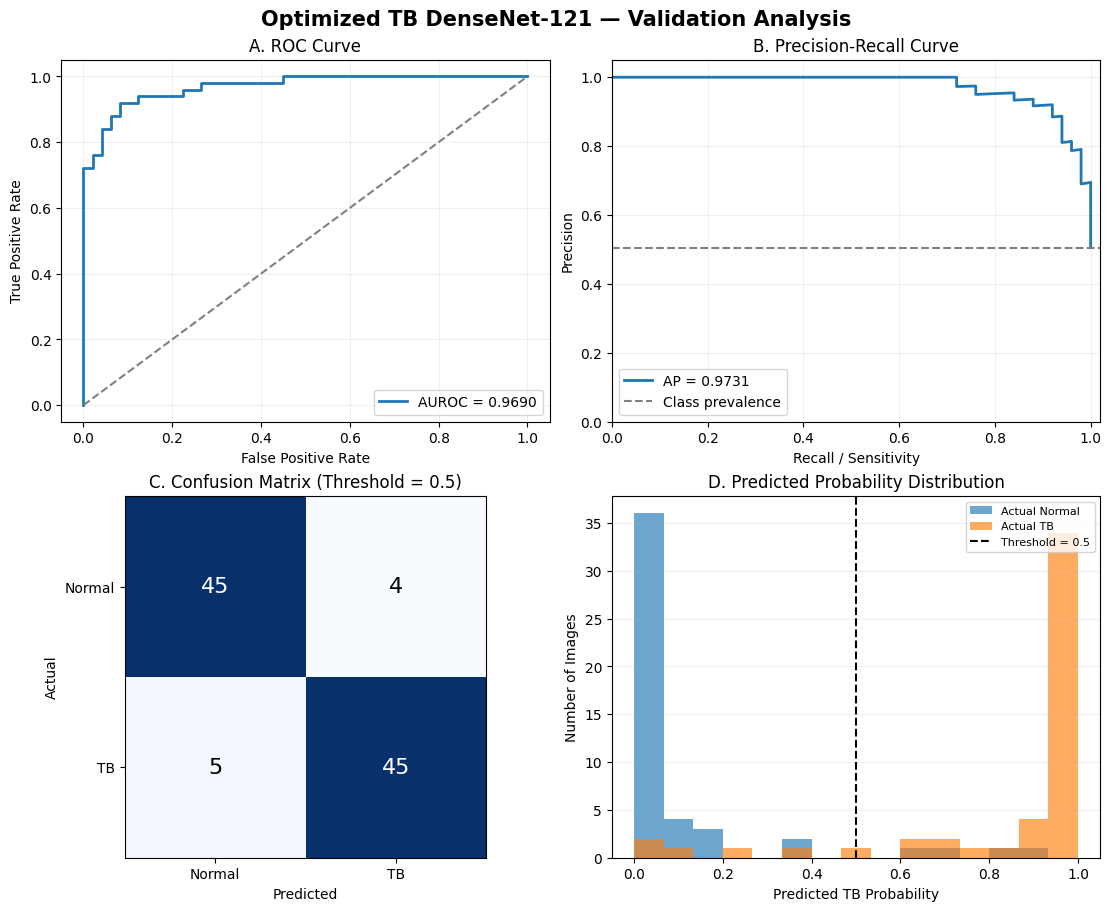

Validation images: 99
ROC AUROC: 0.968980
Average precision: 0.973082
Confusion matrix:
[[45  4]
 [ 5 45]]

Dashboard saved: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/optimization/tb_optimized_clinical_dashboard.png


In [ ]:

# Optimized TB Clinical Performance Dashboard

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)

# Load Existing Validation Predictions
predictions_path = (
    OPT_DIR / "tb_optimized_validation_predictions.csv"
)

pred_df = pd.read_csv(predictions_path)

y_true = pred_df["label"].to_numpy(dtype=int)
y_prob = pred_df["tb_probability"].to_numpy(dtype=float)
y_pred = (y_prob >= 0.5).astype(int)

# Calculate Curves and Confusion Matrix
fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

precision, recall, _ = precision_recall_curve(
    y_true, y_prob
)
avg_precision = average_precision_score(
    y_true, y_prob
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Compact 2x2 Dashboard
fig, axes = plt.subplots(
    2, 2, figsize=(11, 9),
    constrained_layout=True
)

# A. ROC Curve
ax = axes[0, 0]
ax.plot(
    fpr, tpr,
    linewidth=2,
    label=f"AUROC = {roc_auc:.4f}"
)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("A. ROC Curve")
ax.legend(loc="lower right")
ax.grid(alpha=0.2)

# B. Precision-Recall Curve
ax = axes[0, 1]
ax.plot(
    recall, precision,
    linewidth=2,
    label=f"AP = {avg_precision:.4f}"
)
ax.axhline(
    y_true.mean(),
    linestyle="--",
    color="gray",
    label="Class prevalence"
)
ax.set_xlabel("Recall / Sensitivity")
ax.set_ylabel("Precision")
ax.set_title("B. Precision-Recall Curve")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower left")
ax.grid(alpha=0.2)

# C. Confusion Matrix
ax = axes[1, 0]
ax.imshow(cm, cmap="Blues")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            fontsize=16,
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Normal", "TB"])
ax.set_yticklabels(["Normal", "TB"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("C. Confusion Matrix (Threshold = 0.5)")

# D. Probability Distribution
ax = axes[1, 1]

bins = np.linspace(0, 1, 16)

ax.hist(
    y_prob[y_true == 0],
    bins=bins,
    alpha=0.65,
    label="Actual Normal"
)
ax.hist(
    y_prob[y_true == 1],
    bins=bins,
    alpha=0.65,
    label="Actual TB"
)
ax.axvline(
    0.5,
    color="black",
    linestyle="--",
    label="Threshold = 0.5"
)

ax.set_xlabel("Predicted TB Probability")
ax.set_ylabel("Number of Images")
ax.set_title("D. Predicted Probability Distribution")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Optimized TB DenseNet-121 — Validation Analysis",
    fontsize=15,
    fontweight="bold"
)

# Save One Combined Figure
figure_path = (
    OPT_DIR / "tb_optimized_clinical_dashboard.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Validation images:", len(y_true))
print(f"ROC AUROC: {roc_auc:.6f}")
print(f"Average precision: {avg_precision:.6f}")
print("Confusion matrix:")
print(cm)
print("\nDashboard saved:", figure_path)


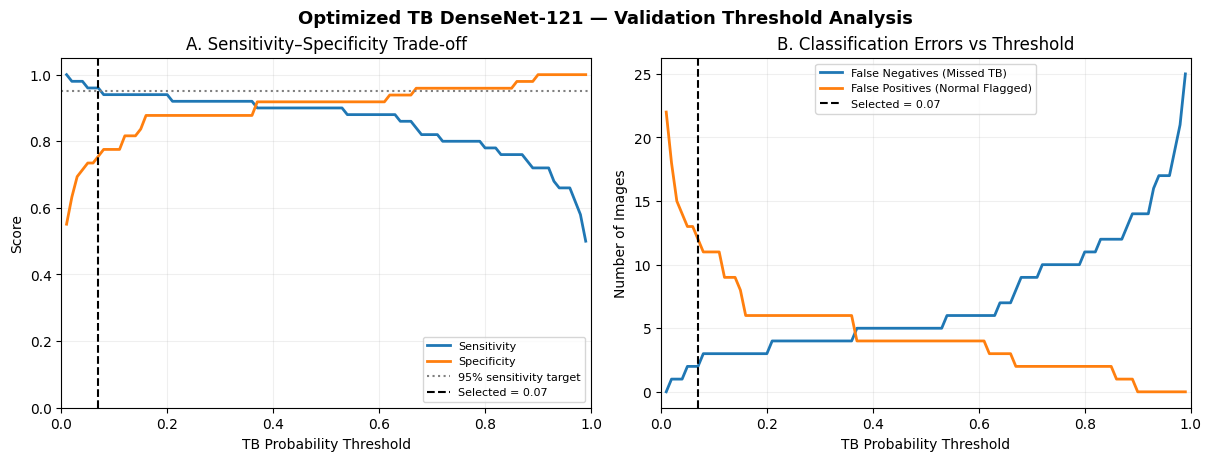


Threshold comparison:
                threshold  sensitivity  specificity  precision      f1  false_negatives  false_positives
Default (0.50)       0.50         0.90       0.9184     0.9184  0.9091              5.0              4.0
Selected             0.07         0.96       0.7551     0.8000  0.8727              2.0             12.0

Selection: Target sensitivity achieved
Selected threshold: 0.07
Figure saved: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/optimization/tb_threshold_analysis.png


In [ ]:

# TB Threshold Analysis — Optimized DenseNet-121

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, precision_score, f1_score

# Load saved validation predictions
pred_df = pd.read_csv(
    OPT_DIR / "tb_optimized_validation_predictions.csv"
)

y_true = pred_df["label"].to_numpy(dtype=int)
y_prob = pred_df["tb_probability"].to_numpy(dtype=float)

assert len(y_true) == 99
assert set(np.unique(y_true)) == {0, 1}

# Evaluate thresholds from 0.01 to 0.99
thresholds = np.round(np.arange(0.01, 1.00, 0.01), 2)

results = []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)

    results.append({
        "threshold": threshold,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "false_negatives": fn,
        "false_positives": fp
    })

threshold_df = pd.DataFrame(results)

# Screening-oriented selection:
# Aim for at least 95% sensitivity.
# Among eligible thresholds, maximize specificity.
# If tied, choose the highest threshold.
target_sensitivity = 0.95

eligible = threshold_df[
    threshold_df["sensitivity"] >= target_sensitivity
]

if not eligible.empty:
    selected = eligible.sort_values(
        ["specificity", "threshold"],
        ascending=[False, False]
    ).iloc[0]
    selection_note = "Target sensitivity achieved"
else:
    selected = threshold_df.sort_values(
        ["sensitivity", "specificity", "threshold"],
        ascending=[False, False, False]
    ).iloc[0]
    selection_note = "Target not achieved; best available"

selected_threshold = float(selected["threshold"])

# Plot sensitivity, specificity, and error counts
fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5),
    constrained_layout=True
)

# A. Sensitivity and specificity
ax = axes[0]

ax.plot(
    threshold_df["threshold"],
    threshold_df["sensitivity"],
    label="Sensitivity",
    linewidth=2
)

ax.plot(
    threshold_df["threshold"],
    threshold_df["specificity"],
    label="Specificity",
    linewidth=2
)

ax.axhline(
    target_sensitivity,
    linestyle=":",
    color="gray",
    label="95% sensitivity target"
)

ax.axvline(
    selected_threshold,
    linestyle="--",
    color="black",
    label=f"Selected = {selected_threshold:.2f}"
)

ax.set(
    title="A. Sensitivity–Specificity Trade-off",
    xlabel="TB Probability Threshold",
    ylabel="Score",
    xlim=(0, 1),
    ylim=(0, 1.05)
)

ax.legend(fontsize=8)
ax.grid(alpha=0.2)

# B. False negatives and false positives
ax = axes[1]

ax.plot(
    threshold_df["threshold"],
    threshold_df["false_negatives"],
    label="False Negatives (Missed TB)",
    linewidth=2
)

ax.plot(
    threshold_df["threshold"],
    threshold_df["false_positives"],
    label="False Positives (Normal Flagged)",
    linewidth=2
)

ax.axvline(
    selected_threshold,
    linestyle="--",
    color="black",
    label=f"Selected = {selected_threshold:.2f}"
)

ax.set(
    title="B. Classification Errors vs Threshold",
    xlabel="TB Probability Threshold",
    ylabel="Number of Images",
    xlim=(0, 1)
)

ax.legend(fontsize=8)
ax.grid(alpha=0.2)

fig.suptitle(
    "Optimized TB DenseNet-121 — Validation Threshold Analysis",
    fontsize=13,
    fontweight="bold"
)

figure_path = OPT_DIR / "tb_threshold_analysis.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

# Compare default and selected thresholds
default = threshold_df.loc[
    np.isclose(threshold_df["threshold"], 0.50)
].iloc[0]

comparison = pd.DataFrame(
    [default, selected],
    index=["Default (0.50)", "Selected"]
)

print("\nThreshold comparison:")
print(
    comparison[
        [
            "threshold",
            "sensitivity",
            "specificity",
            "precision",
            "f1",
            "false_negatives",
            "false_positives"
        ]
    ].round(4).to_string()
)

print("\nSelection:", selection_note)
print(f"Selected threshold: {selected_threshold:.2f}")
print("Figure saved:", figure_path)


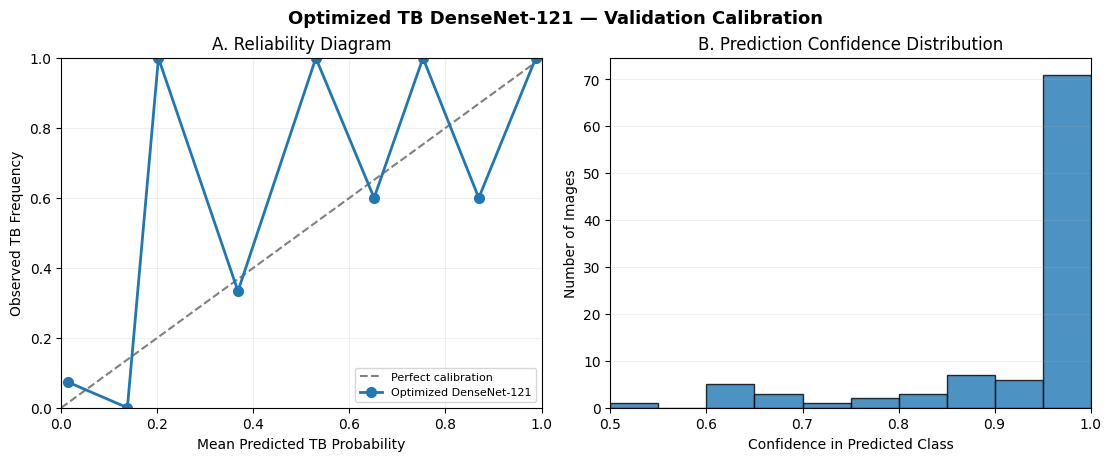


Optimized TB Model — Validation Calibration
---------------------------------------------
Validation images: 99
Brier score: 0.073776
Negative log-likelihood: 0.246726
Expected calibration error (10 bins): 0.070752
Mean prediction confidence: 0.9357

Reliability bins:
 Mean predicted probability  Observed TB frequency  Images
                     0.0142                 0.0732      41
                     0.1377                 0.0000       5
                     0.2023                 1.0000       1
                     0.3679                 0.3333       3
                     0.5301                 1.0000       1
                     0.6514                 0.6000       5
                     0.7531                 1.0000       2
                     0.8693                 0.6000       5
                     0.9881                 1.0000      36

Figure saved: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/optimization/tb_calibration_dashboard.png


In [ ]:

# Optimized TB Probability Calibration Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import brier_score_loss, log_loss
from sklearn.calibration import calibration_curve

# Load optimized model's validation predictions
pred_df = pd.read_csv(
    OPT_DIR / "tb_optimized_validation_predictions.csv"
)

y_true = pred_df["label"].to_numpy(dtype=int)
y_prob = pred_df["tb_probability"].to_numpy(dtype=float)

assert len(y_true) == 99
assert np.all((y_prob >= 0) & (y_prob <= 1))

# 1. Calibration metrics
brier = brier_score_loss(y_true, y_prob)
nll = log_loss(y_true, y_prob, labels=[0, 1])

# Expected Calibration Error (ECE)
# Equal-width bins; empty bins are excluded from the sum.
n_bins = 10
bin_edges = np.linspace(0, 1, n_bins + 1)

bin_ids = np.digitize(
    y_prob, bin_edges[1:-1], right=False
)

bin_confidence = []
bin_accuracy = []
bin_counts = []

ece = 0.0

for i in range(n_bins):
    mask = bin_ids == i
    count = int(mask.sum())

    if count == 0:
        continue

    mean_confidence = float(y_prob[mask].mean())
    observed_frequency = float(y_true[mask].mean())

    bin_confidence.append(mean_confidence)
    bin_accuracy.append(observed_frequency)
    bin_counts.append(count)

    ece += (
        count / len(y_true)
    ) * abs(observed_frequency - mean_confidence)

# 2. Prediction confidence
# Confidence = probability of whichever class was predicted
prediction_confidence = np.maximum(y_prob, 1 - y_prob)

# 3. Combined calibration dashboard
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4.5),
    constrained_layout=True
)

# A. Reliability diagram
ax = axes[0]

ax.plot(
    [0, 1], [0, 1],
    "--",
    color="gray",
    label="Perfect calibration"
)

ax.plot(
    bin_confidence,
    bin_accuracy,
    "o-",
    linewidth=2,
    markersize=7,
    label="Optimized DenseNet-121"
)

ax.set(
    title="A. Reliability Diagram",
    xlabel="Mean Predicted TB Probability",
    ylabel="Observed TB Frequency",
    xlim=(0, 1),
    ylim=(0, 1)
)

ax.legend(fontsize=8)
ax.grid(alpha=0.2)

# B. Prediction confidence distribution
ax = axes[1]

ax.hist(
    prediction_confidence,
    bins=np.linspace(0.5, 1.0, 11),
    edgecolor="black",
    alpha=0.8
)

ax.set(
    title="B. Prediction Confidence Distribution",
    xlabel="Confidence in Predicted Class",
    ylabel="Number of Images",
    xlim=(0.5, 1.0)
)

ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Optimized TB DenseNet-121 — Validation Calibration",
    fontsize=13,
    fontweight="bold"
)

# Save only one figure
figure_path = OPT_DIR / "tb_calibration_dashboard.png"

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 4. Results
print("\nOptimized TB Model — Validation Calibration")
print("-" * 45)
print(f"Validation images: {len(y_true)}")
print(f"Brier score: {brier:.6f}")
print(f"Negative log-likelihood: {nll:.6f}")
print(f"Expected calibration error (10 bins): {ece:.6f}")
print(f"Mean prediction confidence: {prediction_confidence.mean():.4f}")

print("\nReliability bins:")
print(
    pd.DataFrame({
        "Mean predicted probability": bin_confidence,
        "Observed TB frequency": bin_accuracy,
        "Images": bin_counts
    }).round(4).to_string(index=False)
)

print("\nFigure saved:", figure_path)


In [ ]:

# Verify Saved Predictions Against Optimized Checkpoint

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score, brier_score_loss
from tqdm.auto import tqdm

# Existing notebook variables:
# model, val_loader, device, OPT_DIR

saved_df = pd.read_csv(
    OPT_DIR / "tb_optimized_validation_predictions.csv"
)

saved_prob = saved_df["tb_probability"].to_numpy(dtype=float)
saved_labels = saved_df["label"].to_numpy(dtype=int)

# Reload the exact optimized checkpoint
checkpoint_path = OPT_DIR / "lr_3e-04" / "best_model.pth"

state_dict = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)
model.to(device)
model.eval()

# Generate probabilities again
new_probs = []
new_labels = []

with torch.inference_mode():
    for images, labels in tqdm(
        val_loader,
        desc="Verifying optimized checkpoint"
    ):
        images = images.to(device)

        logits = model(images)
        probs = torch.softmax(
            logits.float(), dim=1
        )[:, 1]

        new_probs.extend(probs.cpu().numpy())
        new_labels.extend(labels.numpy())

new_probs = np.array(new_probs)
new_labels = np.array(new_labels)

# Compare image order and probabilities
assert np.array_equal(
    new_labels, saved_labels
), "Validation labels do not match!"

max_difference = np.max(
    np.abs(new_probs - saved_prob)
)

mean_difference = np.mean(
    np.abs(new_probs - saved_prob)
)

print("\nCHECKPOINT VERIFICATION")
print("-" * 45)
print("Images evaluated:", len(new_probs))
print(f"Maximum probability difference: {max_difference:.8f}")
print(f"Mean probability difference: {mean_difference:.8f}")

print("\nRECOMPUTED METRICS")
print("-" * 45)
print(
    "AUROC:",
    f"{roc_auc_score(new_labels, new_probs):.6f}"
)
print(
    "Brier:",
    f"{brier_score_loss(new_labels, new_probs):.6f}"
)

if np.allclose(
    new_probs, saved_prob,
    atol=1e-5,
    rtol=1e-5
):
    print("\nPASS: Saved predictions match the checkpoint.")
else:
    print("\nCHECK NEEDED: Predictions differ from checkpoint.")
    print(
        "Possible causes include preprocessing, "
        "evaluation settings, or a different checkpoint."
    )

print("\nHeld-out test set remains untouched.")


Verifying optimized checkpoint:   0%|          | 0/7 [00:00<?, ?it/s]


CHECKPOINT VERIFICATION
---------------------------------------------
Images evaluated: 99
Maximum probability difference: 0.00000000
Mean probability difference: 0.00000000

RECOMPUTED METRICS
---------------------------------------------
AUROC: 0.968980
Brier: 0.073776

PASS: Saved predictions match the checkpoint.

Held-out test set remains untouched.


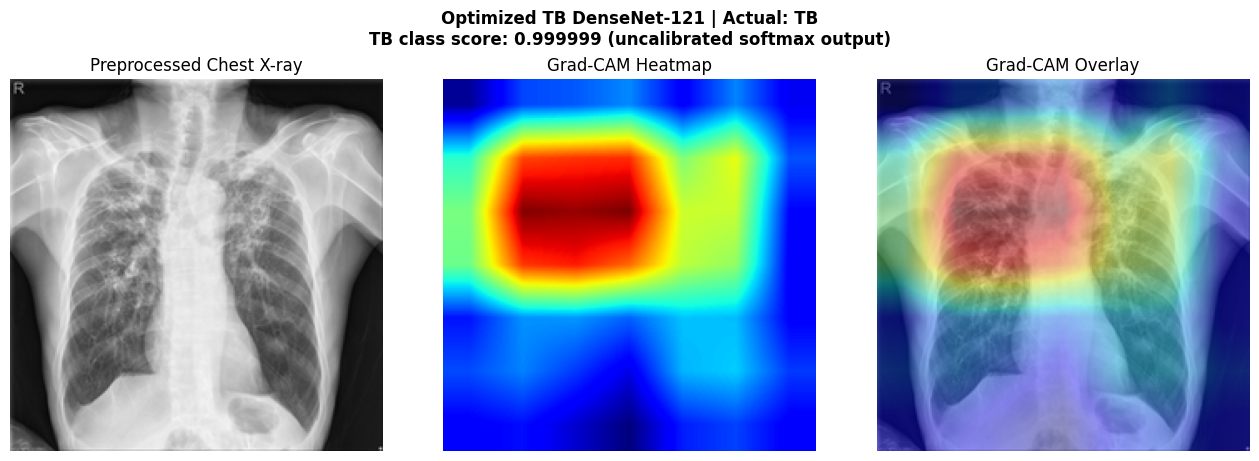

Validation image index: 2
True label: 1
TB class score: 0.999999 (uncalibrated softmax output)


In [ ]:

# Grad-CAM — Optimized TB DenseNet-121 (Corrected)

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load existing validation predictions
# --------------------------------------------------

model.eval()

pred_df = pd.read_csv(
    OPT_DIR / "tb_optimized_validation_predictions.csv"
)

# Choose one correctly classified TB-positive image
correct_tb = pred_df[
    (pred_df["label"] == 1) &
    (pred_df["tb_probability"] >= 0.5)
]

assert len(correct_tb) > 0, "No true-positive examples found."

selected_index = int(correct_tb.index[0])

image_tensor, true_label = val_dataset[selected_index]
input_tensor = image_tensor.unsqueeze(0).to(device)

# --------------------------------------------------
# 2. Prepare original image for visualization
# --------------------------------------------------

mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

display_image = (
    image_tensor.cpu() * std + mean
).clamp(0, 1)

display_image = display_image.permute(
    1, 2, 0
).numpy()

# --------------------------------------------------
# 3. Capture DenseNet features and gradients
# --------------------------------------------------

captured = {}

def capture_features(module, inputs, output):

    captured["activations"] = output

    def save_gradient(gradient):
        captured["gradients"] = gradient.detach()

    # Tensor-level hook avoids DenseNet's
    # in-place ReLU backward-hook error
    output.register_hook(save_gradient)

hook_handle = model.features.norm5.register_forward_hook(
    capture_features
)

# --------------------------------------------------
# 4. Generate Grad-CAM for TB class (class 1)
# --------------------------------------------------

try:
    with torch.enable_grad():

        model.zero_grad(set_to_none=True)

        logits = model(input_tensor)

        tb_score = torch.softmax(
            logits.detach().float(),
            dim=1
        )[0, 1].item()

        # Explain the TB-class logit
        logits[0, 1].backward()

    activations = captured["activations"].detach()
    gradients = captured["gradients"]

    # Average gradients across spatial dimensions
    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    # Weighted combination of feature maps
    cam = (
        weights * activations
    ).sum(dim=1, keepdim=True)

    cam = F.relu(cam)

    # Resize to 224 x 224 input dimensions
    cam = F.interpolate(
        cam,
        size=input_tensor.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    cam = cam[0, 0].detach().cpu().numpy()

    # Normalize heatmap to 0–1
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

finally:
    hook_handle.remove()

# --------------------------------------------------
# 5. Display original, heatmap, and overlay
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 4.5),
    constrained_layout=True
)

# Original chest X-ray
axes[0].imshow(display_image)
axes[0].set_title("Preprocessed Chest X-ray")

# Grad-CAM heatmap
axes[1].imshow(
    cam,
    cmap="jet",
    vmin=0,
    vmax=1
)
axes[1].set_title("Grad-CAM Heatmap")

# Grad-CAM overlay
axes[2].imshow(display_image)

axes[2].imshow(
    cam,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)

axes[2].set_title("Grad-CAM Overlay")

for ax in axes:
    ax.axis("off")

# Scientifically accurate title
fig.suptitle(
    "Optimized TB DenseNet-121 | Actual: TB\n"
    f"TB class score: {tb_score:.6f} "
    "(uncalibrated softmax output)",
    fontsize=12,
    fontweight="bold"
)

plt.show()

# --------------------------------------------------
# 6. Print verification information
# --------------------------------------------------

print("Validation image index:", selected_index)
print("True label:", true_label)

print(
    f"TB class score: {tb_score:.6f} "
    "(uncalibrated softmax output)"
)



OPTIMIZED TB MODEL — CONFIDENCE AUDIT
--------------------------------------------------
Validation images: 99
Correct predictions: 90
Incorrect predictions: 9

HIGH-CONFIDENCE PREDICTIONS
--------------------------------------------------
Confidence >= 99%: 52
Confidence >= 99.9%: 26
Incorrect predictions with confidence >= 99%: 0
Incorrect predictions with confidence >= 99.9%: 0

ALL INCORRECT PREDICTIONS
--------------------------------------------------
                                                                     image_path  label  predicted_class tb_probability confidence
/content/drive/MyDrive/Major_Project/Tuberculosis/data/images/CHNCXR_0418_1.png      1                0       0.012495   0.987505
/content/drive/MyDrive/Major_Project/Tuberculosis/data/images/CHNCXR_0374_1.png      1                0       0.045492   0.954508
/content/drive/MyDrive/Major_Project/Tuberculosis/data/images/CHNCXR_0373_1.png      1                0       0.072837   0.927163
/content/drive/MyD

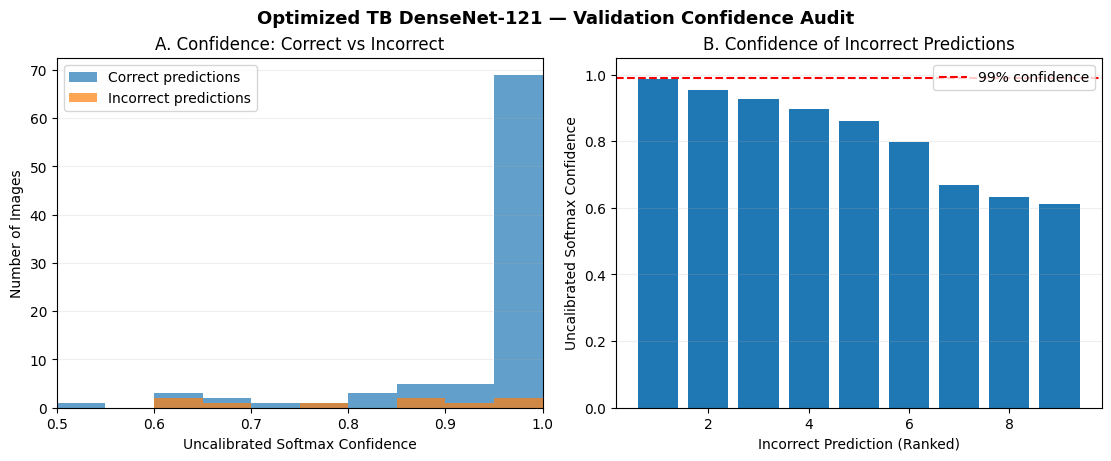


Audit complete.
Scores are uncalibrated softmax outputs.
Held-out test set remains untouched.


In [ ]:

# Confidence Audit — Optimized TB DenseNet-121

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load existing validation predictions
df = pd.read_csv(
    OPT_DIR / "tb_optimized_validation_predictions.csv"
).copy()

# Use threshold 0.50 for the audit
# This separates confidence analysis from our
# provisional screening threshold of 0.07.
df["predicted_class"] = (
    df["tb_probability"] >= 0.50
).astype(int)

df["correct"] = (
    df["predicted_class"] == df["label"]
)

# Confidence in whichever class the model predicted
df["confidence"] = np.where(
    df["predicted_class"] == 1,
    df["tb_probability"],
    1 - df["tb_probability"]
)

# Count very confident predictions
n_total = len(df)
n_correct = int(df["correct"].sum())
n_wrong = int((~df["correct"]).sum())

above_99 = df["confidence"] >= 0.99
above_999 = df["confidence"] >= 0.999

print("OPTIMIZED TB MODEL — CONFIDENCE AUDIT")
print("-" * 50)
print("Validation images:", n_total)
print("Correct predictions:", n_correct)
print("Incorrect predictions:", n_wrong)

print("\nHIGH-CONFIDENCE PREDICTIONS")
print("-" * 50)
print("Confidence >= 99%:", int(above_99.sum()))
print("Confidence >= 99.9%:", int(above_999.sum()))

print(
    "Incorrect predictions with confidence >= 99%:",
    int((above_99 & ~df["correct"]).sum())
)

print(
    "Incorrect predictions with confidence >= 99.9%:",
    int((above_999 & ~df["correct"]).sum())
)

# Examine all incorrect predictions
errors = df.loc[
    ~df["correct"],
    [
        "image_path",
        "label",
        "predicted_class",
        "tb_probability",
        "confidence"
    ]
].sort_values(
    "confidence",
    ascending=False
)

print("\nALL INCORRECT PREDICTIONS")
print("-" * 50)

print(
    errors.to_string(
        index=False,
        formatters={
            "tb_probability": "{:.6f}".format,
            "confidence": "{:.6f}".format
        }
    )
)

# One combined figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4.5),
    constrained_layout=True
)

# A. Confidence distribution: correct vs incorrect
axes[0].hist(
    df.loc[df["correct"], "confidence"],
    bins=np.linspace(0.5, 1.0, 11),
    alpha=0.7,
    label="Correct predictions"
)

axes[0].hist(
    df.loc[~df["correct"], "confidence"],
    bins=np.linspace(0.5, 1.0, 11),
    alpha=0.7,
    label="Incorrect predictions"
)

axes[0].set(
    title="A. Confidence: Correct vs Incorrect",
    xlabel="Uncalibrated Softmax Confidence",
    ylabel="Number of Images",
    xlim=(0.5, 1.0)
)

axes[0].legend()
axes[0].grid(axis="y", alpha=0.2)

# B. Confidence of incorrect predictions
wrong_confidences = errors["confidence"].to_numpy()

axes[1].bar(
    range(1, len(wrong_confidences) + 1),
    wrong_confidences
)

axes[1].axhline(
    0.99,
    linestyle="--",
    color="red",
    label="99% confidence"
)

axes[1].set(
    title="B. Confidence of Incorrect Predictions",
    xlabel="Incorrect Prediction (Ranked)",
    ylabel="Uncalibrated Softmax Confidence",
    ylim=(0, 1.05)
)

axes[1].legend()
axes[1].grid(axis="y", alpha=0.2)

fig.suptitle(
    "Optimized TB DenseNet-121 — Validation Confidence Audit",
    fontsize=13,
    fontweight="bold"
)

plt.show()

print("\nAudit complete.")
print("Scores are uncalibrated softmax outputs.")
print("Held-out test set remains untouched.")


In [14]:

# TB Dataset Split-Integrity and Leakage Audit

import pandas as pd
import hashlib
import re
from pathlib import Path
from collections import defaultdict

# Load existing split CSVs
splits = {
    "Train": pd.read_csv(OUTPUT_DIR / "tb_train.csv"),
    "Validation": pd.read_csv(OUTPUT_DIR / "tb_val.csv"),
    "Test": pd.read_csv(OUTPUT_DIR / "tb_test.csv")
}

print("TB DATASET SPLIT-INTEGRITY AUDIT")
print("=" * 55)

# 1. Verify split sizes and missing files
for name, df in splits.items():
    missing = sum(
        not Path(p).is_file()
        for p in df["image_path"]
    )

    print(
        f"{name}: {len(df)} images | "
        f"Missing files: {missing}"
    )

# 2. Check duplicate paths between splits
print("\nIMAGE PATH OVERLAP")
print("-" * 55)

path_sets = {
    name: {
        str(Path(p).resolve())
        for p in df["image_path"]
    }
    for name, df in splits.items()
}

pairs = [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]

for a, b in pairs:
    overlap = path_sets[a] & path_sets[b]
    print(f"{a} vs {b}: {len(overlap)} overlapping paths")

# 3. Check identical file contents using SHA-256
print("\nIDENTICAL IMAGE CONTENT")
print("-" * 55)

def file_sha256(path):
    hasher = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            hasher.update(chunk)

    return hasher.hexdigest()

hash_sets = {}

for name, df in splits.items():
    hashes = set()

    for path in df["image_path"]:
        if Path(path).is_file():
            hashes.add(file_sha256(path))

    hash_sets[name] = hashes

for a, b in pairs:
    overlap = hash_sets[a] & hash_sets[b]
    print(f"{a} vs {b}: {len(overlap)} identical files")

# 4. Extract candidate subject IDs from Shenzhen filenames
# Example: CHNCXR_0418_1.png -> CHNCXR_0418
# This is a filename-based proxy, NOT a verified patient ID.

print("\nCANDIDATE SUBJECT-ID OVERLAP")
print("-" * 55)

def candidate_subject_id(path):
    stem = Path(path).stem

    match = re.match(
        r"^(CHNCXR_\d+)_\d+$",
        stem,
        flags=re.IGNORECASE
    )

    return match.group(1).upper() if match else None

subject_sets = {}

for name, df in splits.items():
    subject_ids = {
        candidate_subject_id(p)
        for p in df["image_path"]
    }

    subject_ids.discard(None)
    subject_sets[name] = subject_ids

    unknown = sum(
        candidate_subject_id(p) is None
        for p in df["image_path"]
    )

    print(
        f"{name}: {len(subject_ids)} candidate IDs | "
        f"Unrecognized filenames: {unknown}"
    )

for a, b in pairs:
    overlap = subject_sets[a] & subject_sets[b]
    print(
        f"{a} vs {b}: "
        f"{len(overlap)} overlapping candidate IDs"
    )

    if overlap:
        print("Examples:", sorted(overlap)[:5])

# 5. Summary
path_overlap = any(
    path_sets[a] & path_sets[b]
    for a, b in pairs
)

hash_overlap = any(
    hash_sets[a] & hash_sets[b]
    for a, b in pairs
)

subject_overlap = any(
    subject_sets[a] & subject_sets[b]
    for a, b in pairs
)

missing_total = sum(
    not Path(p).is_file()
    for df in splits.values()
    for p in df["image_path"]
)

print("\nAUDIT SUMMARY")
print("=" * 55)

print("Path overlap detected:", path_overlap)
print("Identical file overlap detected:", hash_overlap)
print("Candidate subject overlap detected:", subject_overlap)
print("Missing images:", missing_total)

if (
    not path_overlap
    and not hash_overlap
    and not subject_overlap
    and missing_total == 0
):
    print("\nPASS: No overlap detected by these checks.")
else:
    print("\nREVIEW REQUIRED: Potential split issue detected.")


TB DATASET SPLIT-INTEGRITY AUDIT
Train: 463 images | Missing files: 0
Validation: 99 images | Missing files: 0
Test: 100 images | Missing files: 0

IMAGE PATH OVERLAP
-------------------------------------------------------
Train vs Validation: 0 overlapping paths
Train vs Test: 0 overlapping paths
Validation vs Test: 0 overlapping paths

IDENTICAL IMAGE CONTENT
-------------------------------------------------------
Train vs Validation: 0 identical files
Train vs Test: 0 identical files
Validation vs Test: 0 identical files

CANDIDATE SUBJECT-ID OVERLAP
-------------------------------------------------------
Train: 463 candidate IDs | Unrecognized filenames: 0
Validation: 99 candidate IDs | Unrecognized filenames: 0
Test: 100 candidate IDs | Unrecognized filenames: 0
Train vs Validation: 0 overlapping candidate IDs
Train vs Test: 0 overlapping candidate IDs
Validation vs Test: 0 overlapping candidate IDs

AUDIT SUMMARY
Path overlap detected: False
Identical file overlap detected: False

In [16]:

# TB Near-Duplicate Image Audit — Across Dataset Splits

import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from scipy.fft import dct
from itertools import combinations

# Read existing split files
split_data = {
    "Train": pd.read_csv(OUTPUT_DIR / "tb_train.csv"),
    "Validation": pd.read_csv(OUTPUT_DIR / "tb_val.csv"),
    "Test": pd.read_csv(OUTPUT_DIR / "tb_test.csv")
}

# 64-bit perceptual hash using low-frequency DCT coefficients
def perceptual_hash(image_path):
    with Image.open(image_path) as img:
        gray = img.convert("L").resize(
            (32, 32), Image.Resampling.LANCZOS
        )
        pixels = np.asarray(gray, dtype=np.float32)

    transformed = dct(
        dct(pixels, axis=0, norm="ortho"),
        axis=1, norm="ortho"
    )

    low_freq = transformed[:8, :8].copy()
    values = low_freq.flatten()[1:]  # Exclude DC coefficient
    median = np.median(values)

    return values > median

# Compute hashes
records = []

for split_name, df in split_data.items():
    for image_path in df["image_path"]:
        records.append({
            "split": split_name,
            "image_path": image_path,
            "hash": perceptual_hash(image_path)
        })

# Compare only images from DIFFERENT splits
suspicious = []
minimum_distance = 64

for i, j in combinations(range(len(records)), 2):
    a = records[i]
    b = records[j]

    if a["split"] == b["split"]:
        continue

    distance = int(
        np.count_nonzero(a["hash"] != b["hash"])
    )

    minimum_distance = min(minimum_distance, distance)

    # Small Hamming distance = potentially similar images
    if distance <= 5:
        suspicious.append({
            "Split A": a["split"],
            "Split B": b["split"],
            "Image A": Path(a["image_path"]).name,
            "Image B": Path(b["image_path"]).name,
            "pHash Distance": distance
        })

print("TB NEAR-DUPLICATE IMAGE AUDIT")
print("=" * 55)
print("Total images checked:", len(records))
print("Minimum cross-split pHash distance:", minimum_distance)
print("Suspicious cross-split pairs (distance <= 5):",
      len(suspicious))

if suspicious:
    suspicious_df = pd.DataFrame(suspicious)
    suspicious_df = suspicious_df.sort_values(
        "pHash Distance"
    )

    print("\nPOTENTIAL NEAR-DUPLICATES — REVIEW REQUIRED")
    print(suspicious_df.head(20).to_string(index=False))
else:
    print("\nNo cross-split image pairs flagged at this threshold.")


TB NEAR-DUPLICATE IMAGE AUDIT
Total images checked: 662
Minimum cross-split pHash distance: 2
Suspicious cross-split pairs (distance <= 5): 15

POTENTIAL NEAR-DUPLICATES — REVIEW REQUIRED
Split A    Split B           Image A           Image B  pHash Distance
  Train Validation CHNCXR_0280_0.png CHNCXR_0216_0.png               2
  Train Validation CHNCXR_0197_0.png CHNCXR_0216_0.png               4
  Train Validation CHNCXR_0064_0.png CHNCXR_0292_0.png               4
  Train Validation CHNCXR_0290_0.png CHNCXR_0636_1.png               4
  Train       Test CHNCXR_0179_0.png CHNCXR_0237_0.png               4
  Train Validation CHNCXR_0182_0.png CHNCXR_0473_1.png               4
  Train Validation CHNCXR_0056_0.png CHNCXR_0059_0.png               4
  Train       Test CHNCXR_0409_1.png CHNCXR_0152_0.png               4
  Train       Test CHNCXR_0263_0.png CHNCXR_0152_0.png               4
  Train Validation CHNCXR_0083_0.png CHNCXR_0216_0.png               4
  Train       Test CHNCXR_0039_

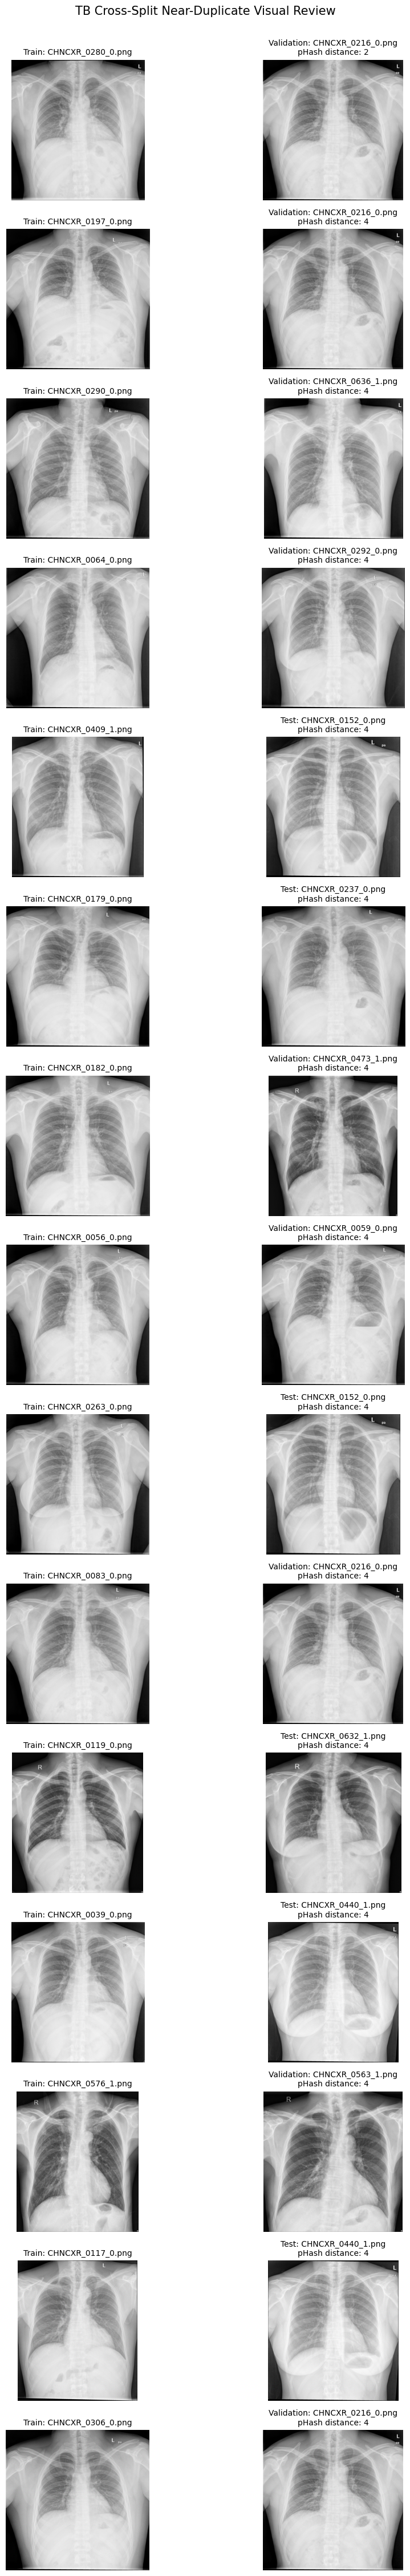

Displayed 15 suspicious image pairs.
No model inference performed.
No new files created.


In [17]:

# Visual Review of TB Near-Duplicate Candidates

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import numpy as np

# Map filenames to their original paths
path_lookup = {
    Path(record["image_path"]).name: record["image_path"]
    for record in records
}

# Sort suspicious pairs by perceptual-hash distance
pairs_to_review = sorted(
    suspicious,
    key=lambda x: x["pHash Distance"]
)

n_pairs = len(pairs_to_review)

fig, axes = plt.subplots(
    n_pairs, 2,
    figsize=(11, max(4, n_pairs * 3))
)

if n_pairs == 1:
    axes = np.array([axes])

for i, pair in enumerate(pairs_to_review):
    name_a = pair["Image A"]
    name_b = pair["Image B"]

    path_a = path_lookup[name_a]
    path_b = path_lookup[name_b]

    with Image.open(path_a) as img:
        image_a = img.convert("L").copy()

    with Image.open(path_b) as img:
        image_b = img.convert("L").copy()

    axes[i, 0].imshow(image_a, cmap="gray")
    axes[i, 1].imshow(image_b, cmap="gray")

    axes[i, 0].set_title(
        f'{pair["Split A"]}: {name_a}',
        fontsize=10
    )
    axes[i, 1].set_title(
        f'{pair["Split B"]}: {name_b}\n'
        f'pHash distance: {pair["pHash Distance"]}',
        fontsize=10
    )

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle(
    "TB Cross-Split Near-Duplicate Visual Review",
    fontsize=15,
    y=1.002
)

plt.tight_layout()
plt.show()

print(f"Displayed {n_pairs} suspicious image pairs.")
print("No model inference performed.")
print("No new files created.")


Selected 4 validation examples.


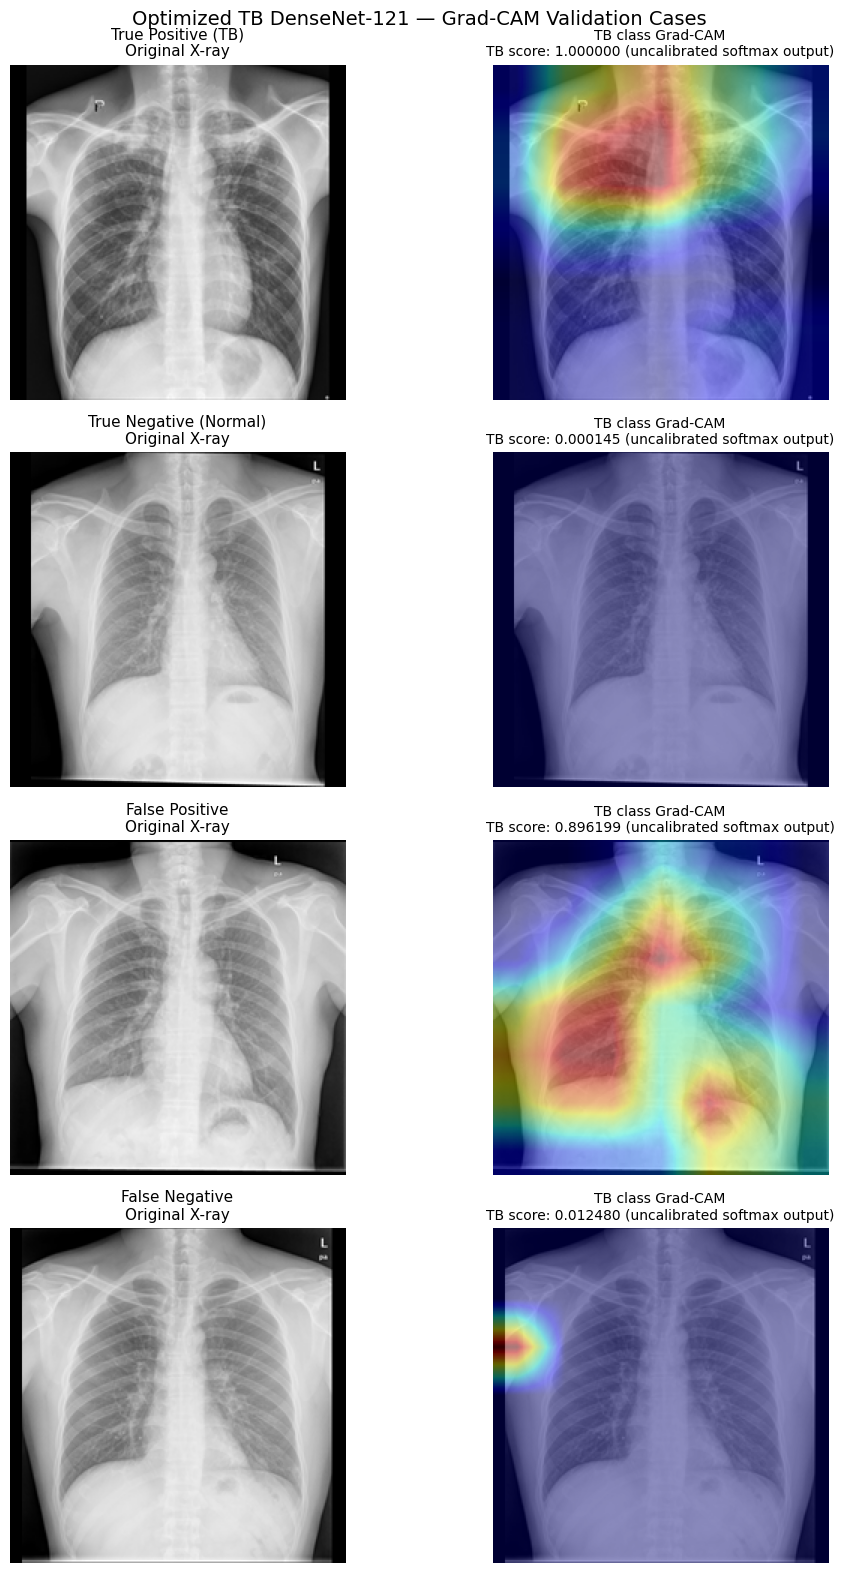


Grad-CAM analysis complete.


In [19]:

# TB Multi-Case Grad-CAM — Optimized DenseNet-121

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

# Load validation predictions saved earlier
pred_path = (
    OPT_DIR / "tb_optimized_validation_predictions.csv"
)
df = pd.read_csv(pred_path)

# Classification at default threshold 0.50
df["predicted"] = (
    df["tb_probability"] >= 0.5
).astype(int)

# Select one example of each outcome
categories = {
    "True Positive (TB)": (1, 1),
    "True Negative (Normal)": (0, 0),
    "False Positive": (0, 1),
    "False Negative": (1, 0)
}

selected = []

for category, (actual, predicted) in categories.items():
    matches = df[
        (df["label"] == actual) &
        (df["predicted"] == predicted)
    ]

    if matches.empty:
        print(f"No example found: {category}")
        continue

    # Choose most confident example for this prediction
    confidence = np.where(
        matches["predicted"].to_numpy() == 1,
        matches["tb_probability"].to_numpy(),
        1 - matches["tb_probability"].to_numpy()
    )

    row = matches.iloc[np.argmax(confidence)]
    selected.append((category, row))

print(f"Selected {len(selected)} validation examples.")

# Grad-CAM using forward hook + tensor gradient hook
# Avoids the inplace-ReLU issue encountered previously

activations = []
gradients = []

def capture_features(module, inputs, output):
    activations.clear()
    gradients.clear()

    activations.append(output.detach())

    if output.requires_grad:
        output.register_hook(
            lambda grad: gradients.append(grad.detach())
        )

hook = model.features.norm5.register_forward_hook(
    capture_features
)

model.eval()

fig, axes = plt.subplots(
    len(selected), 2,
    figsize=(11, 4 * len(selected)),
    squeeze=False
)

try:
    for i, (category, row) in enumerate(selected):

        image_path = row["image_path"]

        # Use EXACT training/validation preprocessing
        image = preprocess_tb_image(image_path)

        x = val_transform(image).unsqueeze(0).to(device)
        x.requires_grad_(True)

        model.zero_grad(set_to_none=True)

        logits = model(x)

        # Explain TB class (index 1) for every case
        tb_score = torch.softmax(
            logits, dim=1
        )[0, 1].item()

        logits[0, 1].backward()

        features = activations[0]
        grads = gradients[0]

        weights = grads.mean(dim=(2, 3), keepdim=True)

        cam = torch.relu(
            (weights * features).sum(dim=1, keepdim=True)
        )

        cam = F.interpolate(
            cam,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()

        # Normalize safely
        cam -= cam.min()
        if cam.max() > 0:
            cam /= cam.max()

        # Original preprocessed X-ray for display
        image_np = np.asarray(image)

        axes[i, 0].imshow(image_np)
        axes[i, 0].set_title(
            f"{category}\nOriginal X-ray",
            fontsize=11
        )

        axes[i, 1].imshow(image_np)
        axes[i, 1].imshow(
            cam,
            cmap="jet",
            alpha=0.40,
            vmin=0,
            vmax=1
        )

        axes[i, 1].set_title(
            f"TB class Grad-CAM\n"
            f"TB score: {tb_score:.6f} "
            f"(uncalibrated softmax output)",
            fontsize=10
        )

        for ax in axes[i]:
            ax.axis("off")

finally:
    hook.remove()

plt.suptitle(
    "Optimized TB DenseNet-121 — Grad-CAM Validation Cases",
    fontsize=14
)
plt.tight_layout()
plt.show()

print("\nGrad-CAM analysis complete.")
